# Spatio-Temporal EEG Transformer (ST-EEGFormer)

This notebook trains and evaluates a Spatio-Temporal EEG Transformer (ST-EEGFormer) using pretrained encoder weights and LoRA adapters to decode binocular rivalry states (Congruent vs. Incongruent Pure).

### 📋 Spatio-Temporal EEG Transformer (ST-EEGFormer) Pipeline Details
* **Input Data**: Raw EEG epochs in `.fif` format.
* **Preprocessing & Feature Extraction**:
  * **Class Balancing**: Random undersampling per subject.
  * **Resampling & Filtering**: All 60 electrodes; resampled to 128 Hz; full window (0.0s to 1.5s); IIR bandpassed (1.0–40.0 Hz).
  * **Channel Alignment**: Rearranges the 60 electrode channels to match the 1D sequential spatial layout expected by ST-EEGFormer.
  * **Standardization**: Per-trial and per-channel Z-score scaling.
* **Model Architecture**:
  * Pre-trained ST-EEGFormer backbone.
  * Low-Rank Adaptation (LoRA) injected into the attention layers to allow parameter-efficient transfer learning with small sample sizes ($r=8$, $\alpha=16$).
  * Linear classifier head.
* **Training & Refitting**: AdamW optimizer ($lr=1e-4$), 2-stage automated refitting.
* **Evaluation**: 5-fold temporal stratified cross-validation.


### Spatio-Temporal EEG Transformer (ST-EEGFormer) Pipeline with LoRA Adapters

This model uses a ViT-style transformer block to process spatial and temporal EEG patches. Parameter-efficient fine-tuning is implemented via LoRA (Low-Rank Adaptation) adapters injected in Attention projection layers, while keeping the base ViT weights frozen.

```mermaid
graph TD
    A[Input Epochs: batch, channels, times] --> B[Reshape to batch*channels, 1, times]
    B --> C[Temporal Patch Embedding: 1D CNN]
    C --> D[Add Spatial & Temporal Positional Embeddings]
    D --> E[Flatten channels & patches to sequence]
    E --> F[Prepend Classification Token: cls_token]
    F --> G[Transformer Encoder Blocks with LoRA adapters]
    G --> H[Extract cls_token state & LayerNorm]
    H --> I[Fully Connected Classifier Head]
    I --> J[Classification Output: Congruent vs Incongruent Pure]
```

In [1]:
# Unified Environment Setup (Local, Colab, Kaggle)
import os
import sys
from pathlib import Path

IS_KAGGLE = os.path.exists('/kaggle/working')
IS_COLAB = 'google.colab' in sys.modules

if IS_KAGGLE:
    print('Detected Kaggle environment. Installing dependencies...')
    !pip install -q mne braindecode[hub] safetensors timm shap huggingface_hub
elif IS_COLAB:
    print('Detected Google Colab environment. Installing dependencies...')
    !pip install -q mne braindecode[hub] safetensors timm shap huggingface_hub
    from google.colab import drive
    drive.mount('/content/drive')

# Locate workspace source directory
try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()

if IS_KAGGLE:
    # Dynamically find the unzipped dataset path
    dataset_root = None
    for root, dirs, files in os.walk('/kaggle/input'):
        if 'tfg-nils-2026-dataset.zip' in files or 'br_analysis' in dirs:
            dataset_root = Path(root)
            break
    SRC_DIR = dataset_root if dataset_root else Path('/kaggle/input/tfg-nils-2026-dataset')
elif IS_COLAB:
    SRC_DIR = Path('/content/drive/MyDrive/TFG_Nils_2026/03_Codi')
else:
    SRC_DIR = NOTEBOOK_DIR.parent

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print(f'Using source directory: {SRC_DIR}')

Detected Google Colab environment. Installing dependencies...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using source directory: /content/drive/MyDrive/TFG_Nils_2026/03_Codi


## Task And Environment Setup

In [8]:
from functools import partial

import torch
import torch.nn as nn
import torch.nn.init as init
from timm.models.vision_transformer import PatchEmbed, Block
import math


class PatchEmbedEEG(nn.Module):
    def __init__(self, patch_size=32, embed_dim=256):
        super().__init__()
        self.p = patch_size
        self.embed_dim = embed_dim
        self.unfold = torch.nn.Unfold(kernel_size=(1, patch_size), stride=int(patch_size))
        self.proj = nn.Linear(self.p, self.embed_dim)

    def forward(self, x):
        output = self.patchify_eeg(x)
        embd = self.proj(output)
        return embd

    def patchify_eeg(self, x):
        # x -> B c L
        bs, c, L = x.shape
        x = x.unsqueeze(2)
        unfolded = self.unfold(x)
        bs, _, seq = unfolded.shape
        # print("unfold:", unfolded.shape)
        unfolded = torch.reshape(unfolded, (bs, c, self.p, seq))
        # print("unfold:", unfolded.shape)
        # Reshape the unfolded tensor to get the desired output shape
        output = unfolded.permute(0, 3, 1, 2)  # Batch, Seq, Ch, L
        return output


class ChannelPositionalEmbed(nn.Module):
    def __init__(self, embedding_dim):
        super(ChannelPositionalEmbed, self).__init__()
        self.channel_transformation = nn.Embedding(145, embedding_dim)
        init.zeros_(self.channel_transformation.weight)

    def forward(self, channel_indices):
        channel_embeddings = self.channel_transformation(channel_indices)
        return channel_embeddings


class TemporalPositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 500):
        super().__init__()
        position = torch.arange(0, max_len).unsqueeze(1)
        div_term = torch.exp((torch.arange(0, d_model, 2) * -(math.log(10000.0) / d_model)).float())
        pe = torch.zeros(1, max_len, d_model)
        pe[0, :, 0::2] = torch.sin(position.float() * div_term)
        pe[0, :, 1::2] = torch.cos(position.float() * div_term)
        self.register_buffer("pe", pe)

    def get_cls_token(self):
        return self.pe[0, 0, :]

    def forward(self, seq_indices):
        batch_size, seq_len = seq_indices.shape
        pe_embeddings = self.pe[0, seq_indices.view(-1)].view(batch_size, seq_len, -1)
        return pe_embeddings


class MaskedAutoencoderViT(nn.Module):
    """Masked Autoencoder with VisionTransformer backbone"""

    def __init__(
        self,
        patch_size=32,
        max_eeg_chans=134,
        embed_dim=1024,
        depth=24,
        num_heads=16,
        decoder_embed_dim=512,
        decoder_depth=8,
        decoder_num_heads=16,
        mlp_ratio=4.0,
        norm_layer=nn.LayerNorm,
        norm_pix_loss=False,
    ):
        super().__init__()

        self.patch_len = patch_size
        # --------------------------------------------------------------------------
        # MAE encoder specifics
        self.patch_embed = PatchEmbedEEG(patch_size=patch_size, embed_dim=embed_dim)

        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))

        # Positional Embeddings
        self.enc_channel_emd = ChannelPositionalEmbed(embed_dim)
        self.enc_temporal_emd = TemporalPositionalEncoding(embed_dim, 512)

        self.dec_channel_emd = ChannelPositionalEmbed(decoder_embed_dim)
        self.dec_temporal_emd = TemporalPositionalEncoding(decoder_embed_dim, 512)

        self.blocks = nn.ModuleList(
            [Block(embed_dim, num_heads, mlp_ratio, qkv_bias=True, norm_layer=norm_layer) for i in range(depth)]
        )
        self.norm = norm_layer(embed_dim)
        # --------------------------------------------------------------------------

        # --------------------------------------------------------------------------
        # MAE decoder specifics
        self.decoder_embed = nn.Linear(embed_dim, decoder_embed_dim, bias=True)

        self.mask_token = nn.Parameter(torch.zeros(1, 1, decoder_embed_dim))

        # self.decoder_pos_embed = ChannelPositionalEmbed(decoder_embed_dim)  # fixed sin-cos embedding

        self.decoder_blocks = nn.ModuleList(
            [
                Block(decoder_embed_dim, decoder_num_heads, mlp_ratio, qkv_bias=True, norm_layer=norm_layer)
                for i in range(decoder_depth)
            ]
        )

        self.decoder_norm = norm_layer(decoder_embed_dim)
        self.decoder_pred = nn.Linear(decoder_embed_dim, patch_size, bias=True)  # decoder to patch
        # --------------------------------------------------------------------------

        self.norm_pix_loss = norm_pix_loss

        self.initialize_weights()

    def initialize_weights(self):
        # initialization
        # initialize (and freeze) pos_embed by sin-cos embedding
        # pos_embed = get_2d_sincos_pos_embed(self.pos_embed.shape[-1], int(self.patch_embed.num_patches**.5), cls_token=True)
        # self.pos_embed.data.copy_(torch.from_numpy(pos_embed).float().unsqueeze(0))

        # decoder_pos_embed = get_2d_sincos_pos_embed(self.decoder_pos_embed.shape[-1], int(self.patch_embed.num_patches**.5), cls_token=True)
        # self.decoder_pos_embed.data.copy_(torch.from_numpy(decoder_pos_embed).float().unsqueeze(0))

        # initialize patch_embed like nn.Linear (instead of nn.Conv2d)
        w = self.patch_embed.proj.weight.data
        torch.nn.init.xavier_uniform_(w.view([w.shape[0], -1]))

        # timm's trunc_normal_(std=.02) is effectively normal_(std=0.02) as cutoff is too big (2.)
        torch.nn.init.normal_(self.cls_token, std=0.02)
        torch.nn.init.normal_(self.mask_token, std=0.02)

        # initialize nn.Linear and nn.LayerNorm
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            # we use xavier_uniform following official JAX ViT:
            torch.nn.init.xavier_uniform_(m.weight)
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.constant_(m.bias, 0)
        elif isinstance(m, nn.LayerNorm):
            nn.init.constant_(m.bias, 0)
            nn.init.constant_(m.weight, 1.0)

    def random_masking(self, x, mask_ratio):
        """
        Perform per-sample random masking by per-sample shuffling.
        Per-sample shuffling is done by argsort random noise.
        x: [N, L, D], sequence
        """
        N, L, D = x.shape  # batch, length, dim
        len_keep = int(L * (1 - mask_ratio))

        noise = torch.rand(N, L, device=x.device)  # noise in [0, 1]

        # sort noise for each sample
        ids_shuffle = torch.argsort(noise, dim=1)  # ascend: small is keep, large is remove
        ids_restore = torch.argsort(ids_shuffle, dim=1)

        # keep the first subset
        ids_keep = ids_shuffle[:, :len_keep]
        x_masked = torch.gather(x, dim=1, index=ids_keep.unsqueeze(-1).repeat(1, 1, D))

        # generate the binary mask: 0 is keep, 1 is remove
        mask = torch.ones([N, L], device=x.device)
        mask[:, :len_keep] = 0
        # unshuffle to get the binary mask
        mask = torch.gather(mask, dim=1, index=ids_restore)

        return x_masked, mask, ids_restore

    def random_masking_demo(self, x, mask_ratio):
        """
        Perform per-sample random masking by per-sample shuffling.
        Per-sample shuffling is done by argsort random noise.
        x: [N, L, D], sequence
        """
        N, L, D = x.shape  # batch, length, dim
        len_keep = int(L * (1 - mask_ratio))

        noise = torch.rand(N, L, device=x.device)  # noise in [0, 1]

        # sort noise for each sample
        ids_shuffle = torch.argsort(noise, dim=1)  # ascend: small is keep, large is remove
        ids_restore = torch.argsort(ids_shuffle, dim=1)

        # keep the first subset
        ids_keep = ids_shuffle[:, :len_keep]
        x_masked = torch.gather(x, dim=1, index=ids_keep.unsqueeze(-1).repeat(1, 1, D))

        # generate the binary mask: 0 is keep, 1 is remove
        mask = torch.ones([N, L], device=x.device)
        mask[:, :len_keep] = 0
        # unshuffle to get the binary mask
        mask = torch.gather(mask, dim=1, index=ids_restore)

        return x_masked, mask, ids_keep, ids_restore

    def mask_use_ids_keep(self, x, ids_keep):
        N, L, D = x.shape  # batch, length, dim
        x_masked = torch.gather(x, dim=1, index=ids_keep.unsqueeze(-1).repeat(1, 1, D))
        return x_masked

    def forward_encoder_demo(self, eeg, chan_idx, mask_ratio, ids_keep=None, mask=None, ids_restore=None):
        # embed patches
        x = self.patch_embed(eeg)
        B, Seq, Ch_all, Dmodel = x.shape
        Seq_total = Seq * Ch_all

        x = x.view(B, Seq_total, Dmodel)
        # add pos embed w/o cls token
        # patch eeg_chan_idx
        eeg_chan_indices = chan_idx.unsqueeze(1).repeat(1, Seq, 1)
        eeg_chan_indices = eeg_chan_indices.view(B, Seq_total)

        # patch eeg_seq_idx
        seq_tensor = torch.arange(1, Seq + 1, device=eeg.device)
        eeg_seq_indices = seq_tensor.unsqueeze(0).unsqueeze(-1).repeat(B, 1, Ch_all)
        eeg_seq_indices = eeg_seq_indices.view(B, Seq_total)
        # print("eeg_embd:", x.shape, "seq:", eeg_seq_indices.shape, "ch:", eeg_chan_indices.shape)
        # Temporal positional encoding: batch, seq, channel, dmodel
        tp_embd = self.enc_temporal_emd(eeg_seq_indices)
        # Channel positional encoding: batch, seq, channel, dmodel
        ch_embd = self.enc_channel_emd(eeg_chan_indices)
        # print("tp_embd:",tp_embd.shape, "ch_embd:", ch_embd.shape)
        x = x + tp_embd + ch_embd
        if ids_keep is None:
            # masking: length -> length * mask_ratio
            x, mask, ids_keep, ids_restore = self.random_masking_demo(x, mask_ratio)
        else:
            x = self.mask_use_ids_keep(x, ids_keep)

        # append cls token
        cls_token = self.cls_token + self.enc_temporal_emd.get_cls_token()
        cls_tokens = cls_token.expand(x.shape[0], -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)

        # apply Transformer blocks
        for blk in self.blocks:
            x = blk(x)
        x = self.norm(x)

        return x, mask, ids_restore, (B, Seq, Ch_all, Dmodel), ids_keep

    def forward_encoder(self, eeg, chan_idx, mask_ratio):
        # 1) Patch‐embed
        x = self.patch_embed(eeg)
        B, Seq, Ch_all, Dmodel = x.shape
        Seq_total = Seq * Ch_all

        # Flatten (Seq, Ch_all) → Seq_total
        x = x.view(B, Seq_total, Dmodel)  # (B, Seq_total, Dmodel)

        # 1a) CHANNEL embeddings (small lookup)
        # If chan_idx is 1‐D (Ch_all,), broadcast to (B, Ch_all)
        if chan_idx.dim() == 1:
            chan_idx = chan_idx.unsqueeze(0).expand(B, -1)  # (B, Ch_all)

        # One embedding call: (B, Ch_all) → (B, Ch_all, Dmodel)
        ch_emb_small = self.enc_channel_emd(chan_idx)  # (B, Ch_all, Dmodel)

        # Tile that across Seq:
        #   (B, Ch_all, Dmodel) → (B, 1, Ch_all, Dmodel)
        #      → repeat_interleave(Seq) → (B, Seq, Ch_all, Dmodel)
        #      → reshape → (B, Seq_total, Dmodel)
        ch_emb = (
            ch_emb_small.unsqueeze(1)  # (B, 1, Ch_all, Dmodel)
            .repeat_interleave(Seq, dim=1)  # (B, Seq, Ch_all, Dmodel)
            .view(B, Seq_total, Dmodel)  # (B, Seq_total, Dmodel)
        )

        # 1b) TEMPORAL embeddings (small lookup)
        # Build [0,1,…,Seq−1] once:
        temp_idx = torch.arange(Seq, device=x.device, dtype=torch.long).unsqueeze(0)  # (1, Seq)
        temp_emb_small_2d = self.enc_temporal_emd(temp_idx)  # (1, Seq, Dmodel)
        temp_emb_small = temp_emb_small_2d.squeeze(0)  # (Seq, Dmodel)

        # Tile that across Ch_all:
        #   (Seq, Dmodel) → (Seq, 1, Dmodel)
        #      → repeat_interleave(Ch_all) → (Seq, Ch_all, Dmodel)
        #      → reshape → (Seq_total, Dmodel)
        temp_emb_flat = (
            temp_emb_small.unsqueeze(1)  # (Seq, 1, Dmodel)
            .repeat_interleave(Ch_all, dim=1)  # (Seq, Ch_all, Dmodel)
            .view(Seq_total, Dmodel)  # (Seq_total, Dmodel)
        )

        # Broadcast time‐embeddings to whole batch: (Seq_total, Dmodel) → (B, Seq_total, Dmodel)
        tp_emb = temp_emb_flat.unsqueeze(0).expand(B, -1, -1)  # (B, Seq_total, Dmodel)

        # 1c) Add channel‐ and time‐embeddings:
        #    x:       (B, Seq_total, Dmodel)
        #    tp_emb:  (B, Seq_total, Dmodel)
        #    ch_emb:  (B, Seq_total, Dmodel)
        x = x + tp_emb + ch_emb

        # 2) MASKING: randomly drop a fraction of patches
        x, mask, ids_restore = self.random_masking(x, mask_ratio)

        # 3) Append cls‐token
        cls_token = self.cls_token + self.enc_temporal_emd.get_cls_token()
        # cls_token: (1, 1, Dmodel); expand to (B, 1, Dmodel)
        cls_tokens = cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)  # (B, 1 + Seq_kept, Dmodel)

        # 4) Transformer blocks + normalization
        for blk in self.blocks:
            x = blk(x)
        x = self.norm(x)

        # Return encoded patches, mask, restore‐indices, and original dims:
        return x, mask, ids_restore, (B, Seq, Ch_all, Dmodel)

    def forward_decoder(self, x, chan_idx, eeg_patch_shape, ids_restore):
        B, Seq, Ch_all, DmodEnc = eeg_patch_shape
        Seq_total = Seq * Ch_all
        # embed tokens
        x = self.decoder_embed(x)

        # append mask tokens to sequence
        mask_tokens = self.mask_token.repeat(x.shape[0], ids_restore.shape[1] + 1 - x.shape[1], 1)
        x_ = torch.cat([x[:, 1:, :], mask_tokens], dim=1)  # no cls token
        x_ = torch.gather(x_, dim=1, index=ids_restore.unsqueeze(-1).repeat(1, 1, x.shape[2]))  # unshuffle
        # print("x_ retun back:", x_.shape)

        # add pos embed
        # patch eeg_chan_idx
        eeg_chan_indices = chan_idx.unsqueeze(1).repeat(1, Seq, 1)
        eeg_chan_indices = eeg_chan_indices.view(B, Seq_total)

        # patch eeg_seq_idx
        seq_tensor = torch.arange(1, Seq + 1, device=x.device)
        eeg_seq_indices = seq_tensor.unsqueeze(0).unsqueeze(-1).repeat(B, 1, Ch_all)
        eeg_seq_indices = eeg_seq_indices.view(B, Seq_total)
        # print("eeg_embd:", x.shape, "seq:", eeg_seq_indices.shape, "ch:", eeg_chan_indices.shape)

        # Temporal positional encoding: batch, seq, channel, dmodel
        tp_embd = self.dec_temporal_emd(eeg_seq_indices)
        # Channel positional encoding: batch, seq, channel, dmodel
        ch_embd = self.dec_channel_emd(eeg_chan_indices)

        x_ = x_ + tp_embd + ch_embd
        cls_ = x[:, :1, :] + self.dec_temporal_emd.get_cls_token()

        x = torch.cat([cls_, x_], dim=1)  # append cls token
        # print("dec_with cls:", x.shape)
        # apply Transformer blocks
        for blk in self.decoder_blocks:
            x = blk(x)
        x = self.decoder_norm(x)

        # predictor projection
        x = self.decoder_pred(x)

        # remove cls token
        x = x[:, 1:, :]
        # print("x_dec output:", x.shape)
        return x

    def forward_loss(self, eeg, pred, mask):
        """
        eeg: [N, Ch, DL]
        pred: [N, L, DL]
        mask: [N, L], 0 is keep, 1 is remove,
        """
        target = self.patch_embed.patchify_eeg(eeg)
        target = target.reshape(pred.shape)
        # print("target shape:", target.shape)

        if self.norm_pix_loss:
            mean = target.mean(dim=-1, keepdim=True)
            var = target.var(dim=-1, keepdim=True)
            target = (target - mean) / (var + 1.0e-6) ** 0.5

        loss = (pred - target) ** 2
        loss = loss.mean(dim=-1)  # [N, L], mean loss per patch

        loss = (loss * mask).sum() / mask.sum()  # mean loss on removed patches
        return loss

    def forward(self, eeg, chan_idx, mask_ratio=0.75):
        latent, mask, ids_restore, eeg_patch_shape = self.forward_encoder(eeg, chan_idx, mask_ratio)
        pred = self.forward_decoder(latent, chan_idx, eeg_patch_shape, ids_restore)  # [N, L, p*p*3]
        loss = self.forward_loss(eeg, pred, mask)
        return loss, pred, mask

    def forward_demo(self, eeg, chan_idx, mask_ratio=0.75, ids_keep=None, mask=None, ids_restore=None):
        latent, mask, ids_restore, eeg_patch_shape, ids_keep = self.forward_encoder_demo(
            eeg, chan_idx, mask_ratio, ids_keep, mask, ids_restore
        )
        pred = self.forward_decoder(latent, chan_idx, eeg_patch_shape, ids_restore)  # [N, L, p*p*3]
        loss = self.forward_loss(eeg, pred, mask)
        return loss, pred, mask, ids_keep, ids_restore

    def unpatchify_eeg(self, x, original_length, Seq, Ch):
        # x: B,L,Leeg
        bs = x.shape[0]
        x = x.view(bs, Seq, Ch, 16)
        fold = torch.nn.Fold(output_size=(1, original_length), kernel_size=(1, self.patch_len), stride=self.patch_len)
        output_permuted = x.permute(0, 2, 3, 1).reshape(
            bs, Ch * self.patch_len, Seq
        )  # (bs, c*kernel_size, num_patches)
        reconstructed = fold(output_permuted)  # (bs, c, 1, L)
        reconstructed = reconstructed.squeeze(2)  # Remove the extra dimension
        return reconstructed


def mae_vit_small_patch16(**kwargs):
    model = MaskedAutoencoderViT(
        patch_size=16,
        embed_dim=512,
        depth=8,
        num_heads=8,
        decoder_embed_dim=384,
        decoder_depth=4,
        decoder_num_heads=16,
        mlp_ratio=4,
        norm_layer=partial(nn.LayerNorm, eps=1e-6),
        **kwargs
    )
    return model

In [9]:
import numpy as np
import pandas as pd
import mne
import torch
from br_analysis import (
    detect_project_paths,
    get_task_config,
    load_raw_epoch_dataset,
    RawEpochSpec,
    get_epochs_grid,
    BinaryTaskConfig,
    COMMON_BAND_RANGES,
    TARGET_BANDS_CLUSTERS,
    temporal_band_features,
    electrode_distance_adjacency,
    load_fused_band_dataset,
    FusedBandSpec,
    temporal_stratified_splits,
)
from br_analysis.torch_training import (
    TorchTrainConfig,
    cross_validate_torch_model,
    standardize_train_test,
    build_dataloader,
    _evaluate,
)
from br_analysis.torch_models import (
    STGNNChebConv,
    EEGNet,
)
from br_analysis.pretrained import (
    prepare_lora_backbone,
    load_backbone_weights,
    BackboneClassifier,
    align_channels_to_steegformer,
)

# from br_analysis import mae_vit_small_patch16
from braindecode.models import InterpolatedLaBraM

TASK_TAG = "c_vs_ip_steegformer"
paths = detect_project_paths("c_vs_i_steegformer")
task_name = "c_vs_ip" if "c_vs_ip" in TASK_TAG else "im_vs_ip"
task = get_task_config(task_name, paths.analysis_root)

mne.set_log_level("WARNING")
RANDOM_SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Working Paths:")
print("  Cache:", paths.cache_dir)
print("  Tables:", paths.tables_dir)
print("  Figures:", paths.figures_dir)

Working Paths:
  Cache: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/c_vs_i_steegformer/cache
  Tables: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/c_vs_i_steegformer/tables
  Figures: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/c_vs_i_steegformer/figures


## Load Epochs And Align Channels

In [10]:
spec = RawEpochSpec(picks=None, bandpass=(1.0, 40.0), resample_sfreq=128.0)
dataset = load_raw_epoch_dataset(paths, task, spec)
X_raw = np.asarray(dataset.X, dtype=np.float32)
y = np.asarray(dataset.y, dtype=np.int64)
subjects = np.asarray(dataset.subjects, dtype=object)
SUBJECT_ID = "P057"
ch_names = list(dataset.channel_names)
times = dataset.times
sfreq = 128.0

# Use native epoch length
TARGET_LEN = X_raw.shape[-1]
X_raw = X_raw

# Align channels to standard 142 channels
X = align_channels_to_steegformer(X_raw, ch_names)

print(f"Aligned X shape: {X.shape} (trials, padded channels, times)")
print(f"Classes: {np.bincount(y)}")

Loading preprocessed dataset from cache: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/cache/dataset_c_vs_ip_subj24_bp1.0_40.0_sf128.0_win0.0_1.5_pkall.joblib
Aligned 60/60 channels to 142-channel format.
Aligned X shape: (5870, 142, 192) (trials, padded channels, times)
Classes: [2935 2935]


## ST-EEGFormer Model Definition & Configuration

In [11]:
def make_model():
    backbone = mae_vit_small_patch16()
    from huggingface_hub import hf_hub_download

    checkpoint_path = None
    if IS_KAGGLE:
        for root, dirs, files in os.walk("/kaggle/input"):
            if "ST-EEGFormer_small_encoder.safetensors" in files:
                checkpoint_path = Path(root) / "ST-EEGFormer_small_encoder.safetensors"
                break
    if checkpoint_path is None:
        checkpoint_path = hf_hub_download(
            repo_id="eugenehp/ST-EEGFormer",
            filename="ST-EEGFormer_small_encoder.safetensors",
        )
    load_backbone_weights(backbone, Path(checkpoint_path), strict=False)
    prepare_lora_backbone(
        backbone,
        include_substrings=("attn", "mlp"),
        exclude_substrings=("head", "classifier", "decoder", "patch_embed", "tokenizer"),
        r=8,
        alpha=16.0,
        dropout=0.05,
        train_classifier=False,
    )
    model = BackboneClassifier(backbone, n_classes=2, example_input=torch.from_numpy(X[:1]))
    return model


train_cfg = TorchTrainConfig(
    epochs=50,
    batch_size=8,
    lr=2e-4,
    weight_decay=1e-4,
    patience=15,
    n_splits=5,
    val_size=0.2,
    random_seed=RANDOM_SEED,
    device=DEVICE,
    progress=True,
)

## 3. Cohort-Wide Training (LoRA Fine-tuning)

We train the LoRA fine-tuned ST-EEGFormer model across all 24 subjects individually and cache the results.

In [12]:
cohort_metrics_path = paths.tables_dir / f"cohort_cv_metrics_{TASK_TAG}.csv"
cohort_fold_metrics_path = paths.tables_dir / f"cohort_fold_metrics_{TASK_TAG}.csv"
subject_ids = pd.unique(subjects).tolist()

if cohort_metrics_path.exists() and cohort_fold_metrics_path.exists():
    print("Loading ST-EEGFormer cohort metrics from cache...")
    df_cohort = pd.read_csv(cohort_metrics_path)
    df_cohort_folds = pd.read_csv(cohort_fold_metrics_path)
else:
    print("Running ST-EEGFormer cohort-wide cross-validation with LoRA adapters...")
    cohort_results = []
    cohort_fold_results = []

    silent_cfg = TorchTrainConfig(
        epochs=train_cfg.epochs,
        batch_size=train_cfg.batch_size,
        lr=train_cfg.lr,
        weight_decay=train_cfg.weight_decay,
        patience=train_cfg.patience,
        n_splits=train_cfg.n_splits,
        val_size=train_cfg.val_size,
        random_seed=train_cfg.random_seed,
        device=train_cfg.device,
        progress=True,
    )

    for sub in subject_ids:
        subj_metrics_path = paths.cache_dir / f"metrics_{TASK_TAG}_sub{sub}.csv"
        if subj_metrics_path.exists():
            print(f"Loading cached metrics for subject {sub}...")
            steeg_metrics = pd.read_csv(subj_metrics_path)
        else:
            print(f"Training/Evaluating subject {sub}...")
            import gc

            gc.collect()
            torch.cuda.empty_cache()
            steeg_metrics, _ = cross_validate_torch_model(
                X,
                y,
                make_model,
                silent_cfg,
                subjects=subjects,
                subject_id=sub,
                save_weights_dir=paths.cache_dir,
                weights_prefix=f"{TASK_TAG}_sub{sub}",
                load_weights=True,
            )
            steeg_metrics.to_csv(subj_metrics_path, index=False)

        cohort_results.append(
            {
                "subject": sub,
                "steegformer_acc": steeg_metrics["test_acc"].mean(),
                "steegformer_auc": steeg_metrics["test_auc"].mean(),
                "steegformer_bal_acc": steeg_metrics["test_balanced_acc"].mean(),
            }
        )

        for idx, row in steeg_metrics.iterrows():
            cohort_fold_results.append(
                {
                    "subject": sub,
                    "model": "ST-EEGFormer",
                    "fold": int(row["fold"]),
                    "test_acc": row["test_acc"],
                    "test_auc": row["test_auc"],
                    "test_balanced_acc": row["test_balanced_acc"],
                }
            )

    df_cohort = pd.DataFrame(cohort_results)
    df_cohort.to_csv(cohort_metrics_path, index=False)
    df_cohort_folds = pd.DataFrame(cohort_fold_results)
    df_cohort_folds.to_csv(cohort_fold_metrics_path, index=False)
    print(f"Saved cohort metrics to: {cohort_metrics_path}")


# Global Cohort CV Summary (mean ± std)
print("\n" + "=" * 50)
print("GLOBAL COHORT CROSS-VALIDATION SUMMARY")
print("=" * 50)
for model_name in df_cohort_folds["model"].unique():
    model_df = df_cohort_folds[df_cohort_folds["model"] == model_name]
    print(f"Model: {model_name}")
    for f in sorted(model_df["fold"].unique()):
        fold_df = model_df[model_df["fold"] == f]
        mean_f = fold_df["test_acc"].mean()
        std_f = fold_df["test_acc"].std()
        print(f"  Fold {f} Accuracy: {mean_f:.4f} ± {std_f:.4f}")
    mean_cv = model_df["test_acc"].mean()
    std_cv = model_df["test_acc"].std()
    print(f"  Average CV Accuracy: {mean_cv:.4f} ± {std_cv:.4f}")
print("=" * 50 + "\n")

Loading ST-EEGFormer cohort metrics from cache...

GLOBAL COHORT CROSS-VALIDATION SUMMARY
Model: ST-EEGFormer
  Fold 1 Accuracy: 0.5064 ± 0.0807
  Fold 2 Accuracy: 0.4997 ± 0.0681
  Fold 3 Accuracy: 0.5119 ± 0.0828
  Fold 4 Accuracy: 0.5351 ± 0.0765
  Fold 5 Accuracy: 0.5367 ± 0.0851
  Average CV Accuracy: 0.5179 ± 0.0790



## 3.5 Cohort-Wide Predictions Extraction

We extract model predictions across all subjects and folds once, caching them in memory so we don't have to reload models in subsequent sections.

In [13]:
# Extract predictions across all subjects and folds
all_y_true = []
all_probs = []
subject_y_trues = {}
subject_y_probs = {}
subject_fold_predictions = {}  # {sub: {fold: (y_true, y_prob)}}

device = torch.device(DEVICE)

print("Extracting cohort predictions across all subjects and folds...")
for sub in subject_ids:
    splits = list(temporal_stratified_splits(y[subjects == sub], train_cfg.n_splits))
    X_sub = X[subjects == sub]
    y_sub = y[subjects == sub]

    sub_y_true = []
    sub_y_prob = []
    subject_fold_predictions[sub] = {}

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        _, X_test = standardize_train_test(X_sub[train_idx], X_sub[test_idx])
        y_test = y_sub[test_idx]

        weights_path = paths.cache_dir / f"{TASK_TAG}_sub{sub}_fold{fold}.pt"
        if weights_path.exists():
            model = make_model().to(device)
            model.load_state_dict(torch.load(weights_path, map_location=device), strict=False)
            model.eval()

            loader = build_dataloader(X_test, y_test, batch_size=train_cfg.batch_size, shuffle=False, device=device)
            _, _, y_true_arr, p = _evaluate(model, loader, device)
            all_y_true.extend(y_true_arr)
            all_probs.extend(p)
            sub_y_true.extend(y_true_arr)
            sub_y_prob.extend(p)
            subject_fold_predictions[sub][fold] = (y_true_arr, p)

    if len(sub_y_true) > 0:
        subject_y_trues[sub] = np.array(sub_y_true)
        subject_y_probs[sub] = np.array(sub_y_prob)

all_y_true = np.array(all_y_true)
all_probs = np.array(all_probs)
all_preds = (all_probs >= 0.5).astype(int)

# ── Save Out-of-Fold predictions to NPZ file ──────────────────────────────────
oof_save_dict = {}
for sub in subject_ids:
    if sub in subject_y_trues and sub in subject_y_probs:
        oof_save_dict[f"{sub}_y_true"] = subject_y_trues[sub]
        oof_save_dict[f"{sub}_prob"] = subject_y_probs[sub]

if oof_save_dict:
    task_name_lc = "c_vs_ip" if "c_vs_ip" in TASK_TAG else "im_vs_ip"
    model_name_lc = "steegformer"
    comp_paths = detect_project_paths("cross_model_comparison")
    out_path = comp_paths.cache_dir / f"oof_predictions_{task_name_lc}_{model_name_lc}.npz"
    out_path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(out_path, **oof_save_dict)

Extracting cohort predictions across all subjects and folds...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:122: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


ST-EEGFormer_small_encoder.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

Loading pretrained model from /root/.cache/huggingface/hub/models--eugenehp--ST-EEGFormer/snapshots/24c1f616ea0287fa6e4dba6d9278b34de772f80a/ST-EEGFormer_small_encoder.safetensors...


## 4. Single-Subject Detailed Performance Comparison (P057)

=== ST-EEGFormer Classification Report (Subject P057) ===
                  precision    recall  f1-score   support

       Congruent       0.63      0.55      0.59       100
Incongruent_Pure       0.60      0.68      0.64       100

        accuracy                           0.61       200
       macro avg       0.62      0.61      0.61       200
    weighted avg       0.62      0.61      0.61       200



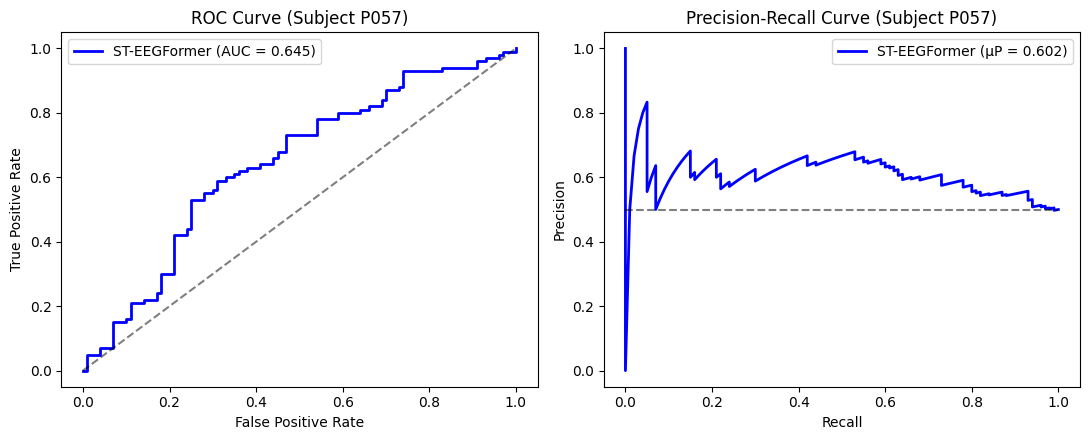

In [14]:
from sklearn.metrics import classification_report, roc_curve, precision_recall_curve, auc
import matplotlib.pyplot as plt

# Extract P057-specific predictions from the cohort predictions
y_true_all = subject_y_trues[SUBJECT_ID]
probs = subject_y_probs[SUBJECT_ID]
preds = (probs >= 0.5).astype(int)

print("=== ST-EEGFormer Classification Report (Subject P057) ===")
print(classification_report(y_true_all, preds, target_names=[task.class_0, task.class_1], zero_division=0.0))

# Plot ROC/PR curves
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.5))
fpr, tpr, _ = roc_curve(y_true_all, probs)
ax_roc.plot(fpr, tpr, label=f"ST-EEGFormer (AUC = {auc(fpr, tpr):.3f})", color="blue", linewidth=2)
ax_roc.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax_roc.set_title("ROC Curve (Subject P057)")
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.legend()

prec, rec, _ = precision_recall_curve(y_true_all, probs)
ax_pr.plot(rec, prec, label=f"ST-EEGFormer (μP = {auc(rec, prec):.3f})", color="blue", linewidth=2)
ax_pr.plot([0, 1], [0.5, 0.5], "k--", alpha=0.5)
ax_pr.set_title("Precision-Recall Curve (Subject P057)")
ax_pr.set_xlabel("Recall")
ax_pr.set_ylabel("Precision")
ax_pr.legend()

plt.tight_layout()
plt.savefig(paths.figures_dir / f"roc_pr_{TASK_TAG}_P057.png", dpi=180, bbox_inches="tight")
plt.show()

In [15]:
# Zipping outputs for easy download when running on Kaggle
if IS_KAGGLE:
    import shutil

    print("Zipping outputs...")
    shutil.make_archive("/kaggle/working/outputs", "zip", "/kaggle/working/TFG_Nils_2026/04_Anàlisi")
    print("Zipped outputs saved to /kaggle/working/outputs.zip")